<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 3 · Models</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Assumes <a href="/blogs/horizon-frequency-and-target.html">Horizon, frequency and target</a>.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

Gradient-boosted trees such as LightGBM won the M5 forecasting competition[^1], and they forecast well once a series is rewritten as a table — one row per time step, lagged values and calendar terms as columns. They also carry one hard limit that the table hides: a tree's prediction is built from averages of training targets, so it cannot forecast outside the range it was trained on. On 32 years of monthly Mauna Loa $\text{CO}_2$, a LightGBM model of the concentration never forecasts above its training maximum of $355.6\text{ ppm}$ while the real record climbs to $373.8$, and barely beats repeating last year. Modelling the year-on-year change instead cuts the error threefold, because changes stay in range. Afterwards you should be able to build the lag table, explain the ceiling from the boosting update, choose a target that keeps the model in range, and validate it in time order rather than with shuffled folds, which here overstate accuracy 7.5-fold.
:::

In [1]:
import sys
import warnings
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.model_selection import KFold, TimeSeriesSplit

# fallcolor is the site's colour module at the repo root, not an installed package.
sys.path.insert(
    0,
    str(
        next(
            p
            for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "fallcolor.py").exists()
        )
    ),
)
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
warnings.formatwarning = lambda msg, cat, *_, **__: f"{cat.__name__}: {msg}\n"

PARAMS = dict(
    n_estimators=400,
    learning_rate=0.05,
    num_leaves=15,
    min_child_samples=10,
    random_state=0,
    deterministic=True,
    verbose=-1,
)

## A series becomes a table

The data are the Scripps flask record from Mauna Loa, Hawaii, shipped with statsmodels: weekly $\text{CO}_2$ in parts per million by volume (ppmv) from 1958 to 2001[^2]. Concentration is a *state*, so it is resampled to monthly by averaging, not summing (see [Horizon, frequency and target](../horizon-frequency-and-target.qmd)). Five months with no samples are filled by linear interpolation.

In [2]:
weekly = sm.datasets.co2.load_pandas().data["co2"]
co2 = weekly.resample("MS").mean()
print(
    f"{len(co2)} months, {co2.index[0]:%Y-%m} to {co2.index[-1]:%Y-%m}; {co2.isna().sum()} empty months interpolated"
)
co2 = co2.interpolate()

526 months, 1958-03 to 2001-12; 5 empty months interpolated


A tree model has no notion of order. It sees rows, so order has to be written into the columns. Each row is one month; the target is that month's value, and the features are values the model would know one step earlier — the last three months, the same month a year ago — plus the month of the year, encoded as a point on a circle so that December sits next to January.

In [3]:
LAGS = (1, 2, 3, 12)


def lag_table(series):
    X = pd.DataFrame({f"lag_{k}": series.shift(k) for k in LAGS})
    month = series.index.month
    X["month_sin"] = np.sin(2 * np.pi * month / 12)
    X["month_cos"] = np.cos(2 * np.pi * month / 12)
    return X


lag_table(co2).assign(target=co2).dropna().head(4).round(2)

,lag_1,lag_2,lag_3,lag_12,month_sin,month_cos,target
1959-03-01,316.70,315.50,314.70,316.10,1.00,0.00,316.73
1959-04-01,316.73,316.70,315.50,317.20,0.87,-0.50,317.68
1959-05-01,317.68,316.73,316.70,317.43,0.50,-0.87,318.32
1959-06-01,318.32,317.68,316.73,316.53,0.00,-1.00,318.02


This is a one-step-ahead table, $h = 1$. To forecast many months from a single origin, the model is applied **recursively**: predict next month, append the prediction to the series as if observed, rebuild that row's lags, repeat. [Direct vs recursive in Darts](../darts-direct-vs-recursive.qmd) compares this with fitting one model per horizon.

We train on 1958–1989 and forecast all 144 months of 1990–2001 from the end of 1989.

In [4]:
ORIGIN = pd.Timestamp("1989-12-01")
train = co2[:ORIGIN]
test = co2[ORIGIN + pd.offsets.MonthBegin() :]


def forecast_recursive(model, history, steps):
    s = history.copy()
    for _ in range(steps):
        t = s.index[-1] + pd.offsets.MonthBegin()
        s.loc[t] = np.nan
        s.loc[t] = model.predict(lag_table(s).iloc[[-1]])[0]
    return s.iloc[-steps:]


def rmse(forecast):
    return float(np.sqrt(((forecast - test) ** 2).mean()))


print(
    f"train {len(train)} months, max {train.max():.1f} ppmv | test {len(test)} months, max {test.max():.1f} ppmv"
)

train 382 months, max 355.6 ppmv | test 144 months, max 373.8 ppmv


## Trees cannot extrapolate

Gradient boosting builds its prediction as a sum of small trees[^3]. Starting from a constant $F_0$, each round adds a tree $h_m$ fitted to what the current model still gets wrong:

$$F_m(\mathbf{x}) = F_{m-1}(\mathbf{x}) + \eta\, h_m(\mathbf{x})$$

where $\mathbf{x}$ is one row of features and $\eta$ is the learning rate ($0.05$ here). For squared error, "what it gets wrong" is simply the residual $y_i - F_{m-1}(\mathbf{x}_i)$, and each leaf of $h_m$ predicts the *average* residual of the training rows that land in it. Every term in the sum is therefore an average of training quantities. However far the inputs move — even a lag of $370\text{ ppmv}$ the model never saw — each tree routes it into an existing leaf and returns that leaf's value. The model can only ever output numbers assembled from the training targets.

On a series with a trend, that is a ceiling. Fit the model to the concentration itself, and compare it with the simplest honest baseline, which repeats the last observed year:

In [5]:
X_level = lag_table(train).dropna()
level_model = lgb.LGBMRegressor(**PARAMS).fit(X_level, train.loc[X_level.index])
level_fc = forecast_recursive(level_model, train, len(test))

seasonal_naive = pd.Series(
    train.iloc[-12:].to_numpy()[np.arange(len(test)) % 12], index=test.index
)

print(
    f"highest forecast {level_fc.max():.2f} ppmv  vs  training maximum {train.max():.2f} ppmv"
)
print(
    f"RMSE: seasonal naive {rmse(seasonal_naive):.2f} | LightGBM on the level {rmse(level_fc):.2f} ppmv"
)

highest forecast 355.14 ppmv  vs  training maximum 355.60 ppmv
RMSE: seasonal naive 10.68 | LightGBM on the level 9.52 ppmv


The forecast never exceeds the highest value in its training data, while the observed record rises another $18\text{ ppmv}$. Twelve years of boosting barely beat copying 1989 forward.

## Model the change, not the level

The fix is to choose a target that *stays* inside the training range. The concentration keeps rising; its year-on-year change does not. The **seasonal difference**

$$d_t = y_t - y_{t-12}$$

removes both the trend and the seasonal cycle, leaving the annual growth rate, which stays inside the range it occupied in training. We fit the same model, with the same features, to $d_t$, forecast it recursively, and rebuild the concentration one year at a time with $\hat{y}_t = y_{t-12} + \hat{d}_t$:

In [6]:
growth = (co2 - co2.shift(12)).dropna()
growth_train = growth[:ORIGIN]

X_growth = lag_table(growth_train).dropna()
growth_model = lgb.LGBMRegressor(**PARAMS).fit(
    X_growth, growth_train.loc[X_growth.index]
)
growth_fc = forecast_recursive(growth_model, growth_train, len(test))

rebuilt = train.copy()
for t, d_hat in growth_fc.items():
    rebuilt.loc[t] = rebuilt.loc[t - pd.DateOffset(years=1)] + d_hat
diff_fc = rebuilt.loc[test.index]

scores = pd.DataFrame(
    {
        "RMSE (ppmv)": [rmse(seasonal_naive), rmse(level_fc), rmse(diff_fc)],
        "2001 mean (ppmv)": [
            seasonal_naive[-12:].mean(),
            level_fc[-12:].mean(),
            diff_fc[-12:].mean(),
        ],
    },
    index=["seasonal naive", "LightGBM, level", "LightGBM, seasonal difference"],
)
scores.loc["observed"] = [np.nan, test[-12:].mean()]
scores.round(2)

,RMSE (ppmv),2001 mean (ppmv)
seasonal naive,10.68,352.87
"LightGBM, level",9.52,354.39
"LightGBM, seasonal difference",3.33,364.81
observed,NaN,370.85


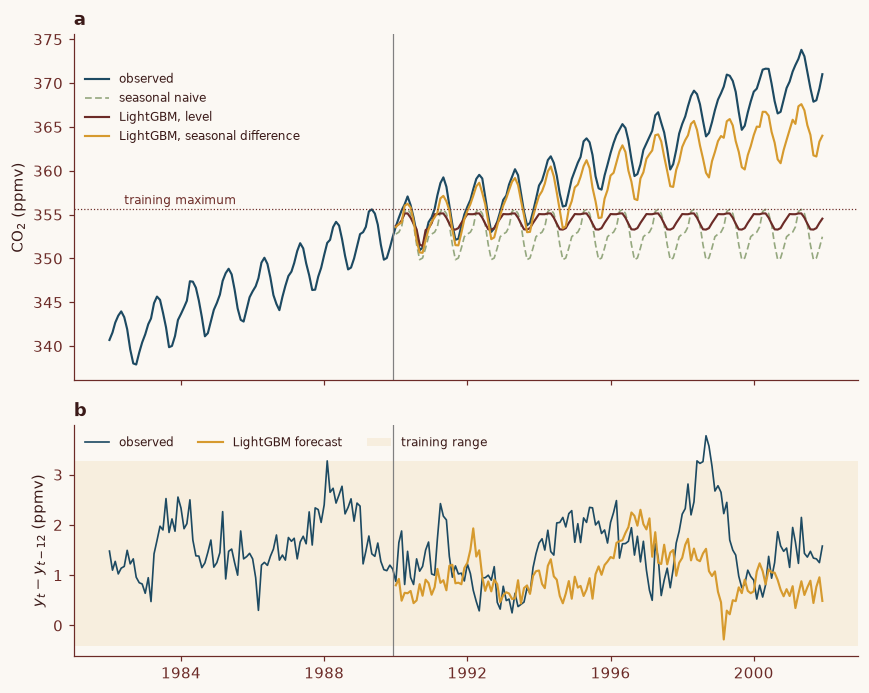

In [7]:
fig, (a, b) = plt.subplots(
    2, 1, figsize=(8, 6.4), sharex=True, gridspec_kw={"height_ratios": [3, 2]}
)
c_obs, c_diff, c_level, c_naive = fallcolor.palette.discrete("default")

window = co2["1982":]
a.plot(window.index, window, color=c_obs, lw=1.4, label="observed")
a.plot(
    seasonal_naive.index,
    seasonal_naive,
    color=c_naive,
    lw=1.1,
    ls=(0, (4, 2)),
    label="seasonal naive",
)
a.plot(level_fc.index, level_fc, color=c_level, lw=1.4, label="LightGBM, level")
a.plot(
    diff_fc.index, diff_fc, color=c_diff, lw=1.4, label="LightGBM, seasonal difference"
)
a.axhline(train.max(), color=c_level, lw=0.8, ls=":")
a.text(
    pd.Timestamp("1982-06-01"),
    train.max() + 0.6,
    "training maximum",
    color=c_level,
    fontsize=8,
)
a.axvline(ORIGIN, color="0.5", lw=0.8)
a.set_ylabel("CO$_2$ (ppmv)")
a.legend(frameon=False, fontsize=8, loc="upper left", bbox_to_anchor=(0.0, 0.92))
a.set_title("a", loc="left", fontweight="bold")

g = growth["1982":]
b.plot(g.index, g, color=c_obs, lw=1.1, label="observed")
b.plot(growth_fc.index, growth_fc, color=c_diff, lw=1.4, label="LightGBM forecast")
b.axhspan(
    growth_train.min(),
    growth_train.max(),
    color=c_diff,
    alpha=0.10,
    lw=0,
    label="training range",
)
b.axvline(ORIGIN, color="0.5", lw=0.8)
b.set_ylabel("$y_t - y_{t-12}$ (ppmv)")
b.legend(frameon=False, fontsize=8, loc="upper left", ncol=3)
b.set_title("b", loc="left", fontweight="bold")

for ax in (a, b):
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
plt.show()

<strong>Figure 1 | A tree model of a rising series stops at its training maximum; a model of the change does not.</strong> <strong>a</strong>, Monthly mean $\text{CO}_2$ at Mauna Loa (observed) and three 144-month forecasts issued from December 1989 (vertical line): repeating 1989 (seasonal naive), LightGBM fitted to the concentration (level), and LightGBM fitted to the year-on-year change and rebuilt into a concentration (seasonal difference). The dotted line marks the highest concentration in the training data. <strong>b</strong>, The year-on-year change: observed, and as forecast by the seasonal-difference model, against the range of changes seen in training (shaded). Observed changes stay inside that range except for one excursion in 1998, the record growth year that followed the 1997–98 El Niño, so the remaining error in <strong>a</strong> is not a range limit.

Modelling the change cuts the error about threefold, and the forecast follows the trend. It still ends about $6\text{ ppmv}$ low. Panel **b** rules out the obvious suspect — the real growth rate barely left the training range — so the cause is elsewhere:

In [8]:
by_decade = {f"{d}s": growth[str(d) : str(d + 9)].mean() for d in (1960, 1970, 1980)}
print(
    "observed growth, training decades:",
    {k: round(float(v), 2) for k, v in by_decade.items()},
    "ppmv/yr",
)
observed_growth = growth[test.index].mean()
print(
    f"1990-2001: forecast growth {growth_fc.mean():.2f}, observed {observed_growth:.2f} ppmv/yr"
)
print(
    f"shortfall over {len(test) // 12} years: {(observed_growth - growth_fc.mean()) * len(test) / 12:.1f} ppmv"
)

observed growth, training decades: {'1960s': 0.86, '1970s': 1.23, '1980s': 1.61} ppmv/yr
1990-2001: forecast growth 0.99, observed 1.50 ppmv/yr
shortfall over 12 years: 6.0 ppmv


The growth rate was not stationary either. It roughly doubled between the 1960s and the 1980s, and a model that treats the change as a stationary quantity reverts its forecast towards an average weighted by the slow early decades. A shortfall of half a part per million per year, held for twelve years, is the whole $6\text{ ppmv}$ gap. Differencing removed the trend in the level and exposed the trend in the rate. Whatever target you choose, check what trend is left in *it*.

## Validate in time order

A forecast is only as good as the test it passed. The usual scikit-learn habit, shuffled $k$-fold cross-validation, scores the level model on one-step predictions using months scattered through the whole record, so every test month has training months on both sides of it, at the same concentration. `TimeSeriesSplit` instead trains on an expanding past and scores on the block that follows, which is how the model will be used:

In [9]:
X_all = lag_table(co2).dropna()
y_all = co2.loc[X_all.index]


def cv_rmse(splitter):
    errors = []
    for fit_idx, score_idx in splitter.split(X_all):
        m = lgb.LGBMRegressor(**PARAMS).fit(X_all.iloc[fit_idx], y_all.iloc[fit_idx])
        errors.append(
            np.sqrt(
                ((m.predict(X_all.iloc[score_idx]) - y_all.iloc[score_idx]) ** 2).mean()
            )
        )
    return float(np.mean(errors))


shuffled, ordered = (
    cv_rmse(KFold(5, shuffle=True, random_state=0)),
    cv_rmse(TimeSeriesSplit(5)),
)
print(
    f"one-step RMSE: shuffled 5-fold {shuffled:.2f} | time-ordered 5-fold {ordered:.2f} ppmv  ({ordered / shuffled:.1f}x)"
)

one-step RMSE: shuffled 5-fold 0.65 | time-ordered 5-fold 4.92 ppmv  (7.5x)


Same model, same features, same data. Shuffled folds report an error several times smaller, because they quietly ask the model to interpolate between months it has seen rather than extend past the last one. They hide exactly the failure this module is about.

Three further choices follow the same logic and are covered elsewhere in this series: which features may legally enter the table ([Feature engineering with feature_engine](1_feature_engineering.ipynb)), which loss to boost when the target is bounded ([Cross-entropy for bounded targets](../lightgbm-cross-entropy-bounded-target.qmd)), and how to combine a boosted model with others ([Ensemble models](2_ensemble_models.ipynb)).

## Key takeaways

- Rewrite a series as a table — one row per time step, lags and calendar terms as columns — and a gradient-boosted tree model becomes a strong forecaster.
- The boosting update $F_m = F_{m-1} + \eta\,h_m$ adds averages of training residuals, so the model cannot forecast outside the range of its training targets. On a trending series that is a hard ceiling.
- Choose a target that stays in range: a difference, a ratio or a detrended residual, then rebuild the level. Then check the new target for a trend of its own — here the growth rate itself was accelerating, and the model could not see it.
- Always compare against a naive baseline. Here a boosted model of the level barely beat repeating last year.
- Validate in time order. Shuffled $k$-fold scored this model 7.5 times more accurate than it is.

### Data and code

- **Data**: Mauna Loa monthly means computed from the Scripps weekly flask record[^2], as distributed with `statsmodels.datasets.co2`; public domain.
- **Software**: [LightGBM](https://lightgbm.readthedocs.io)[^4], scikit-learn and pandas.

## References

[^1]: Makridakis, S., Spiliotis, E. & Assimakopoulos, V. M5 accuracy competition: results, findings, and conclusions. *Int. J. Forecast.* **38**, 1346–1364 (2022). https://doi.org/10.1016/j.ijforecast.2021.11.013
[^2]: Keeling, C. D. & Whorf, T. P. Atmospheric CO2 concentrations derived from flask air samples at sites in the SIO network. In *Trends: A Compendium of Data on Global Change* (Carbon Dioxide Information Analysis Center, Oak Ridge National Laboratory, 2004).
[^3]: Friedman, J. H. Greedy function approximation: a gradient boosting machine. *Ann. Stat.* **29**, 1189–1232 (2001). https://doi.org/10.1214/aos/1013203451
[^4]: Ke, G. et al. LightGBM: a highly efficient gradient boosting decision tree. *Adv. Neural Inf. Process. Syst.* **30**, 3146–3154 (2017). https://papers.nips.cc/paper/6907-lightgbm-a-highly-efficient-gradient-boosting-decision-tree

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/baselines-first.html"><span>Previous</span>Baselines first</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/forecast/2_ensemble_models.html"><span>Next</span>Ensemble models</a></div>
<!-- CURRICULUM_FOOTER_END -->